# The dataset

Step 5 of `docs/unet-baseline-plan.md`. A look at the generated data before training, to decide two
things:

- **Normalization**: how to scale the model's input and target.
- **Loss weighting**: whether plain MSE (mean squared error) treats short and long elapsed times
  fairly.

A training sample is a pair of snapshots from one run: a start `z_a`, a later `z_b`, and the elapsed
time `ΔT = t_b - t_a`. The planned target is the change `z_b - z_a` divided by the start's relief
(max minus min height). This notebook measures how big that target is.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.colors import LightSource
from pathlib import Path

DATA = Path("../artifacts/data/full")

In [2]:
def load(split):
    path = DATA / split
    snapshots = np.load(path / "snapshots.npy", mmap_mode="r")
    with np.load(path / "params.npz") as f:
        params = dict(f)
    return snapshots, params, json.loads((path / "meta.json").read_text())


snapshots, params, meta = load("train")
times = params["times"]
cfg = meta["config"]
print("snapshots:", snapshots.shape, snapshots.dtype, f"({snapshots.nbytes / 1e9:.1f} GB)")
print("snapshot spacing:", times[1], "yr, last:", times[-1], "yr")
print("generated with:", meta["versions"])

snapshots: (8000, 51, 128, 128) float32 (26.7 GB)
snapshot spacing: 1000.0 yr, last: 50000.0 yr
generated with: {'landlab': '2.9.2', 'richdem': '0.3.4', 'numpy': '1.26.4'}


## 1. Parameters

`D` and `U` are drawn as ratios to `K_ref`. `K` is what the simulator used, after the adjustment with
`m`.

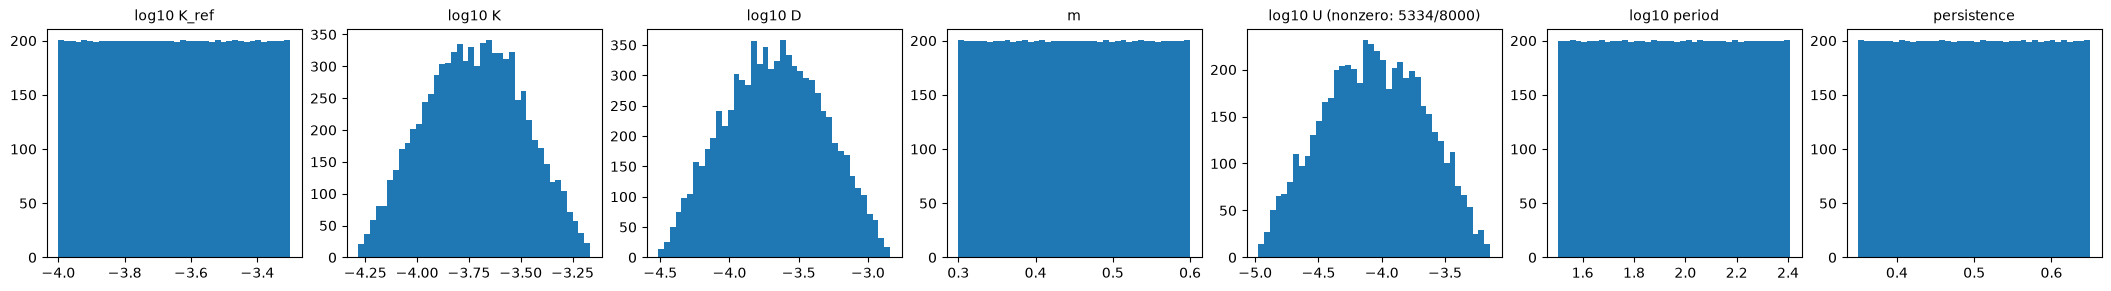

In [3]:
keys = ["K_ref", "K", "D", "m", "U", "period", "persistence"]
log_keys = {"K_ref", "K", "D", "U", "period"}
fig, axes = plt.subplots(1, len(keys), figsize=(3 * len(keys), 2.8), layout="constrained")
for ax, key in zip(axes, keys):
    values = params[key][params[key] > 0] if key == "U" else params[key]
    ax.hist(np.log10(values) if key in log_keys else values, bins=40)
    ax.set_title(f"log10 {key}" if key in log_keys else key, fontsize=10)
    if key == "U":
        ax.set_title(f"log10 U (nonzero: {len(values)}/{len(params['U'])})", fontsize=10)
plt.show()

## 2. Examples

Six random runs at five times, and the total change. Each picture is colored by its own height range.

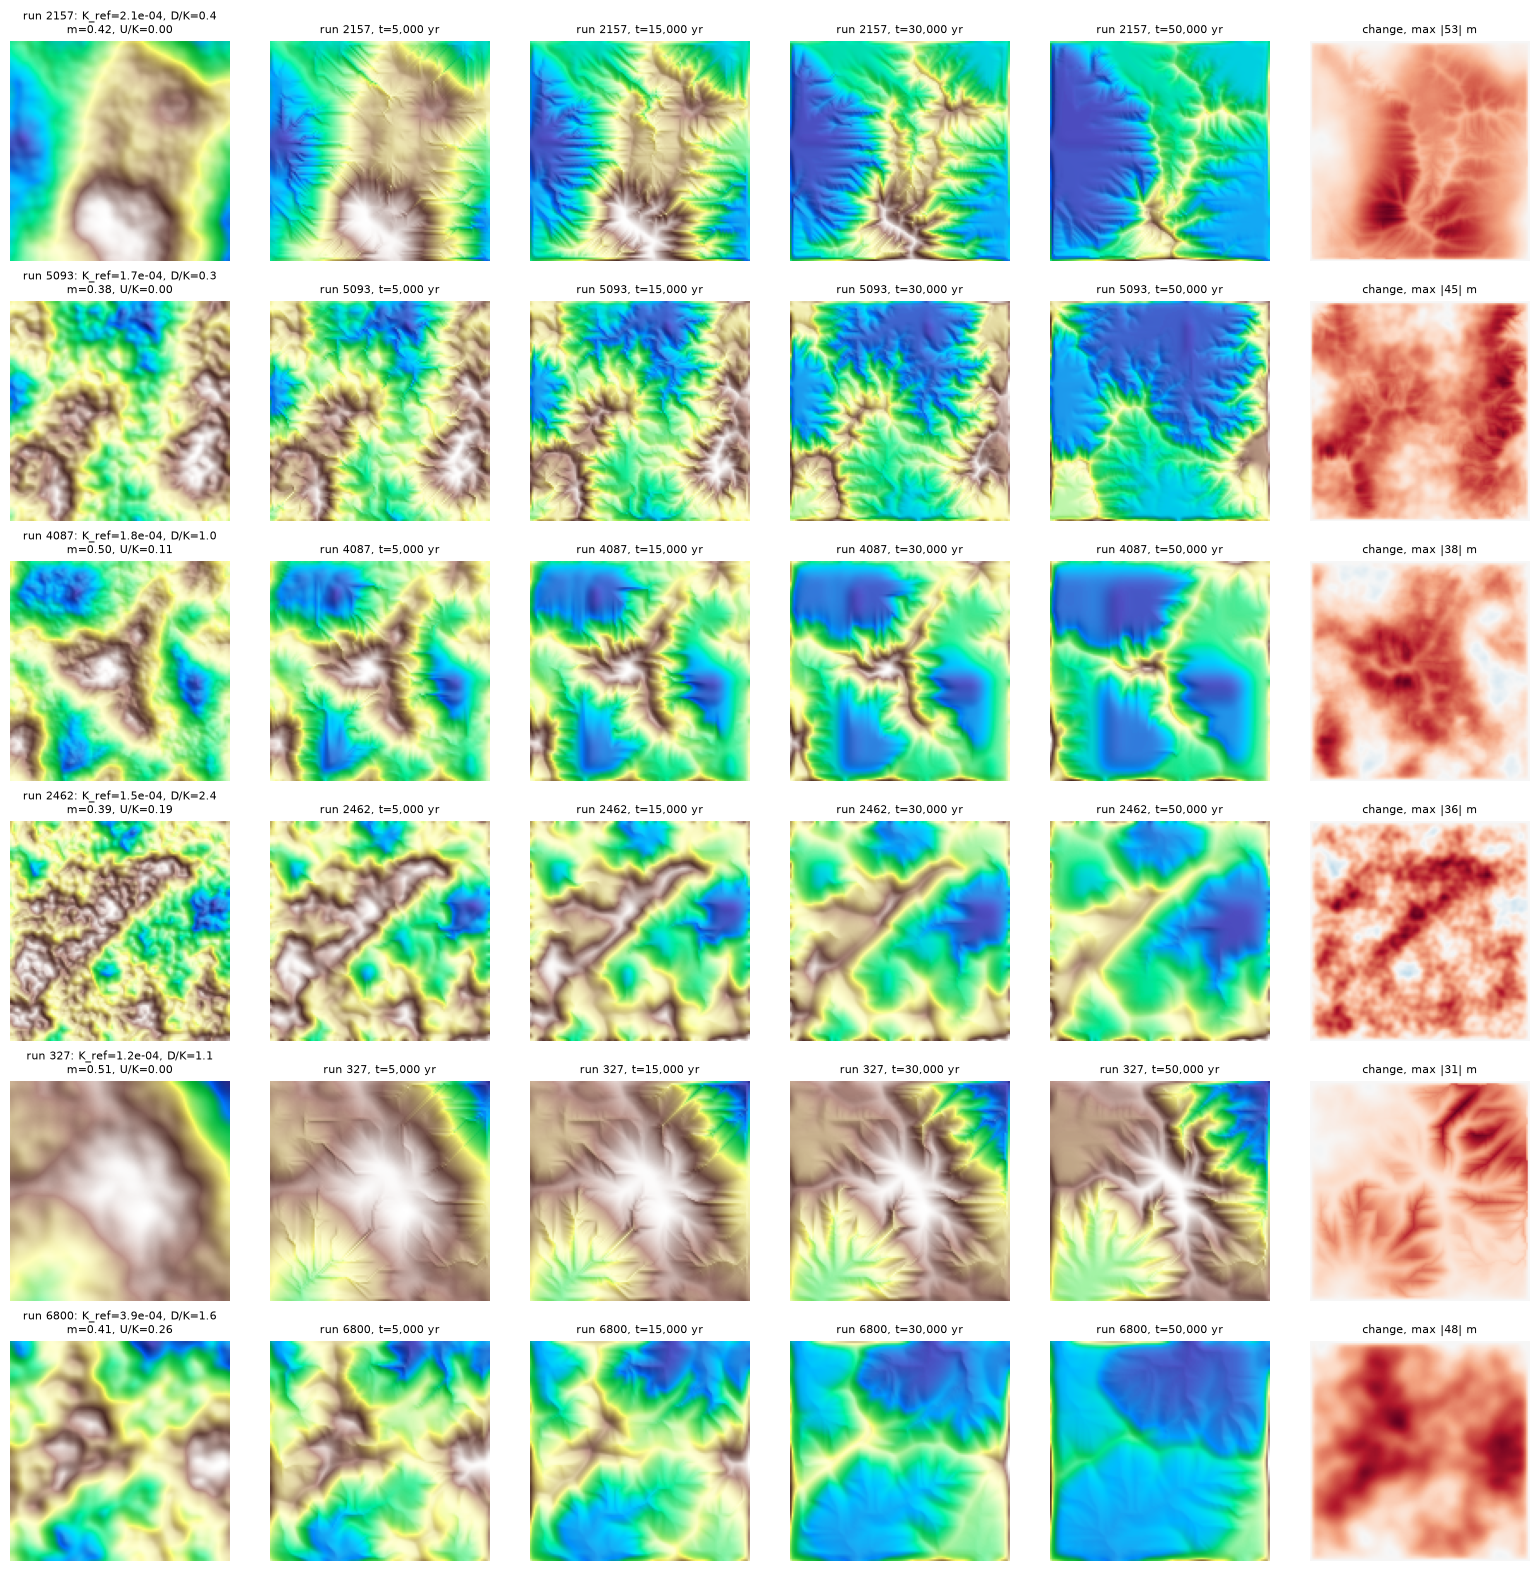

In [4]:
def hillshade(ax, z, title=""):
    light = LightSource(azdeg=315, altdeg=45)
    ax.imshow(light.shade(np.asarray(z, dtype=float), cmap=plt.cm.terrain, blend_mode="soft"), origin="lower")
    ax.set_title(title, fontsize=8)
    ax.set_axis_off()


rng = np.random.default_rng(0)
runs = rng.choice(len(snapshots), 6, replace=False)
picks = [0, 5, 15, 30, 50]
fig, axes = plt.subplots(len(runs), len(picks) + 1, figsize=(2.6 * (len(picks) + 1), 2.6 * len(runs)), layout="constrained")
for row, r in zip(axes, runs):
    for ax, s in zip(row, picks):
        title = f"run {r}, t={times[s]:,.0f} yr"
        if s == 0:
            title = f"run {r}: K_ref={params['K_ref'][r]:.1e}, D/K={params['D'][r] / params['K_ref'][r]:.1f}\nm={params['m'][r]:.2f}, U/K={params['U'][r] / params['K_ref'][r]:.2f}"
        hillshade(ax, snapshots[r, s], title)
    change = snapshots[r, -1] - snapshots[r, 0]
    limit = np.abs(change).max()
    row[-1].imshow(change, origin="lower", cmap="RdBu", vmin=-limit, vmax=limit)
    row[-1].set_title(f"change, max |{limit:.0f}| m", fontsize=8)
    row[-1].set_axis_off()
plt.show()

## 3. Size of the target against elapsed time

For a sample of runs and start snapshots, compute the RMS (root mean square) of the normalized change
`(z_b - z_a) / relief(z_a)` for every later snapshot. The edges never change, so only interior nodes
count.

In [5]:
sample = rng.choice(len(snapshots), 800, replace=False)
starts = [0, 10, 25, 40]
records = []  # (run, start index, elapsed snapshots, rms)
for r in np.sort(sample):
    s = np.asarray(snapshots[r], dtype=np.float64)[:, 1:-1, 1:-1]
    for a in starts:
        relief = s[a].max() - s[a].min()
        d = (s[a + 1:] - s[a]) / relief
        rms = np.sqrt((d ** 2).mean(axis=(1, 2)))
        for k, value in enumerate(rms, start=1):
            records.append((r, a, k, value))
records = np.array(records)
run_idx, start_idx, lag, rms = records[:, 0].astype(int), records[:, 1].astype(int), records[:, 2].astype(int), records[:, 3]
dT = lag * times[1]
print(f"{len(records):,} pairs from {len(sample)} runs")

100,000 pairs from 800 runs


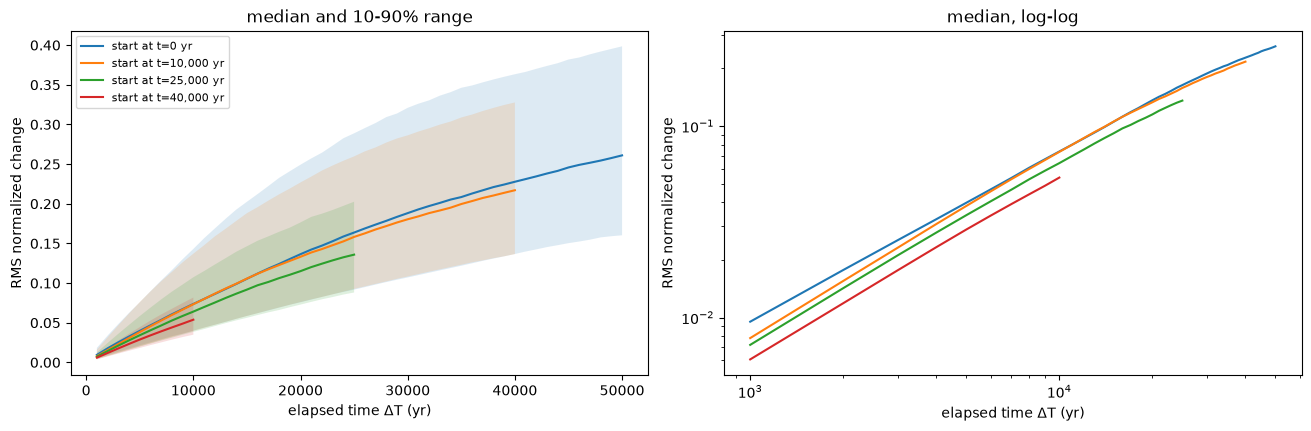

ΔT=  1,000 yr: median RMS 0.0095
ΔT=  5,000 yr: median RMS 0.0398
ΔT= 10,000 yr: median RMS 0.0737
ΔT= 25,000 yr: median RMS 0.1637
ΔT= 50,000 yr: median RMS 0.2610


In [6]:
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.2), layout="constrained")
for start in starts:
    sel = start_idx == start
    lags = np.unique(lag[sel])
    med = np.array([np.median(rms[sel & (lag == k)]) for k in lags])
    lo = np.array([np.percentile(rms[sel & (lag == k)], 10) for k in lags])
    hi = np.array([np.percentile(rms[sel & (lag == k)], 90) for k in lags])
    a.plot(lags * times[1], med, label=f"start at t={times[start]:,.0f} yr")
    a.fill_between(lags * times[1], lo, hi, alpha=0.15)
    b.loglog(lags * times[1], med, label=f"start at t={times[start]:,.0f} yr")
a.set(xlabel="elapsed time ΔT (yr)", ylabel="RMS normalized change", title="median and 10-90% range")
b.set(xlabel="elapsed time ΔT (yr)", ylabel="RMS normalized change", title="median, log-log")
a.legend(fontsize=8)
plt.show()

sel = start_idx == 0
for k in [1, 5, 10, 25, 50]:
    print(f"ΔT={k * times[1]:>7,.0f} yr: median RMS {np.median(rms[sel & (lag == k)]):.4f}")

## 4. What sets the size of the change

The plan noted that, without uplift, the result depends on `K·T` and `D/K`. If so, `K_ref · ΔT`
should explain most of the spread in the change at a given `ΔT`. Points are pairs starting at `t = 0`,
colored by uplift.

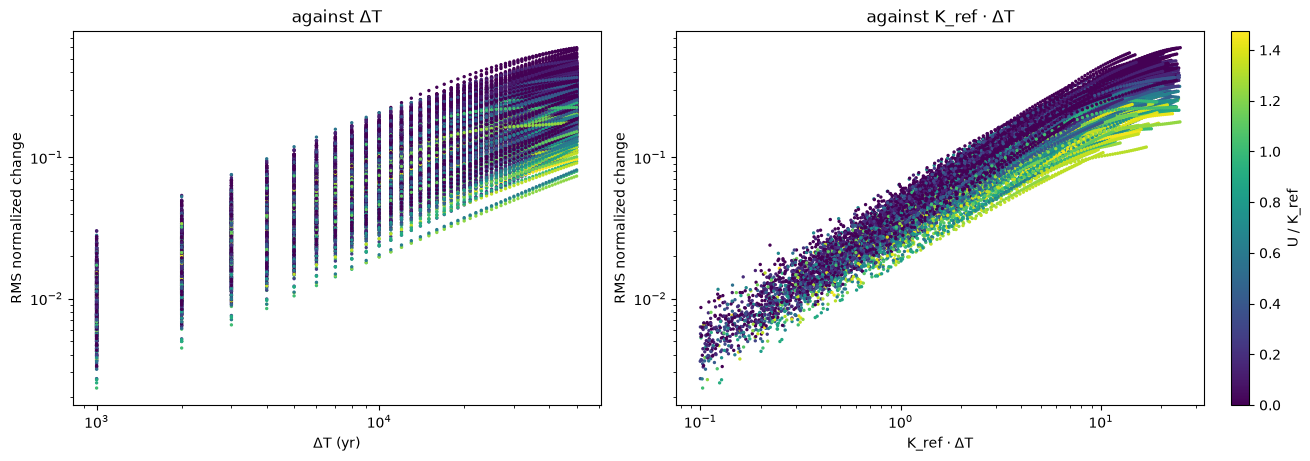

correlation of log RMS with log ΔT: 0.862
correlation of log RMS with log K_ref·ΔT: 0.956


In [7]:
sel = start_idx == 0
kt = params["K_ref"][run_idx[sel]] * dT[sel]
uplift = params["U"][run_idx[sel]] / params["K_ref"][run_idx[sel]]
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
sc = a.scatter(dT[sel], rms[sel], c=uplift, s=2, cmap="viridis")
a.set(xscale="log", yscale="log", xlabel="ΔT (yr)", ylabel="RMS normalized change", title="against ΔT")
sc = b.scatter(kt, rms[sel], c=uplift, s=2, cmap="viridis")
b.set(xscale="log", yscale="log", xlabel="K_ref · ΔT", ylabel="RMS normalized change", title="against K_ref · ΔT")
plt.colorbar(sc, ax=b, label="U / K_ref")
plt.show()

for name, x in [("ΔT", dT[sel]), ("K_ref·ΔT", kt)]:
    r = np.corrcoef(np.log(x), np.log(rms[sel]))[0, 1]
    print(f"correlation of log RMS with log {name}: {r:.3f}")

## 5. How plain MSE weights each elapsed time

Plain MSE adds squared errors. If the model's error is a fixed fraction of the target, each
example's share of the loss scales with the square of its target size. The table shows each `ΔT`'s
share of the total, if `ΔT` is drawn uniformly over the snapshot pairs.

In [8]:
sel = start_idx == 0
lags = np.unique(lag[sel])
mean_sq = np.array([np.mean(rms[sel & (lag == k)] ** 2) for k in lags])
share = mean_sq / mean_sq.sum()
for k in [1, 2, 5, 10, 25, 50]:
    i = k - 1
    print(f"ΔT={k * times[1]:>7,.0f} yr: {share[i]:7.3%} of the loss, "
          f"{share[i] / (1 / len(lags)):.2f}x its fair share")
print(f"\nlargest / smallest weight: {mean_sq.max() / mean_sq.min():.0f}x")

ΔT=  1,000 yr:  0.007% of the loss, 0.00x its fair share
ΔT=  2,000 yr:  0.025% of the loss, 0.01x its fair share
ΔT=  5,000 yr:  0.129% of the loss, 0.06x its fair share
ΔT= 10,000 yr:  0.443% of the loss, 0.22x its fair share
ΔT= 25,000 yr:  1.915% of the loss, 0.96x its fair share
ΔT= 50,000 yr:  4.300% of the loss, 2.15x its fair share

largest / smallest weight: 579x


## 6. Distribution of values in the target

Per-node values of the normalized change at a few elapsed times. Heavy tails mean a few nodes (the
river channels) carry most of the squared error.

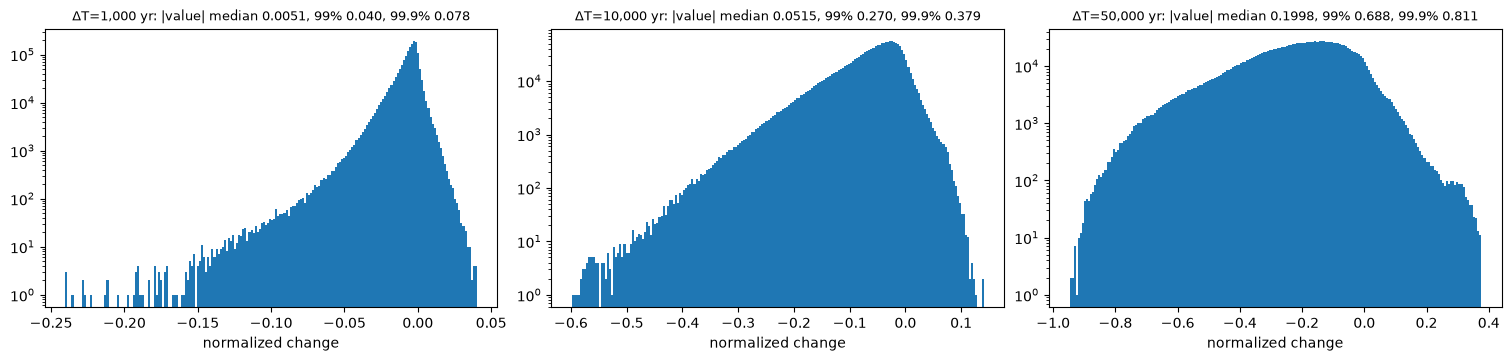

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.5), layout="constrained")
for ax, k in zip(axes, [1, 10, 50]):
    values = np.concatenate([
        ((np.asarray(snapshots[r, k], dtype=float) - snapshots[r, 0]) / np.ptp(snapshots[r, 0]))[1:-1, 1:-1].ravel()
        for r in sample[:100]
    ])
    ax.hist(values, bins=200, log=True)
    q = np.percentile(np.abs(values), [50, 99, 99.9])
    ax.set_title(f"ΔT={k * times[1]:,.0f} yr: |value| median {q[0]:.4f}, 99% {q[1]:.3f}, 99.9% {q[2]:.3f}", fontsize=9)
    ax.set_xlabel("normalized change")
plt.show()